In [1]:
from datasets import load_dataset
from mne.decoding.csp import CSP
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, ShuffleSplit, KFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
import numpy as np
from sklearn.utils import resample
from tqdm.auto import tqdm
import json
import pandas as pd
import pickle
import seaborn as sns
import matplotlib.pyplot as plt

from data.physionet_datamodule import PhysionetDatamodule

sns.set_theme(context='paper', style='white', palette='colorblind', font_scale=.8, font='serif', rc={'font.family': 'serif','figure.figsize': (6.3, 3)})
# Adjust path to import custom modules
import os
import sys
sys.path.append(os.path.abspath(".."))
%load_ext autoreload
%autoreload 2
from utils import get_chan_names, adapt_channel_names_to_mne
import mne
mne.set_log_level('INFO')
mne.use_log_level('INFO')
import  logging
logging.basicConfig(level=logging.INFO)
from data.affect_prediction_datamodule import AffectPredictionDataModule
DATASET_PATH = "../data/physionet_datamodule"
DATA_DIR = os.path.expanduser("~/Projects/datasets/physiomi/")
#DATA_DIR = "$HOME/projects/datasets/censored/"


# Demonstrate CSP
has been cut. Look at arousal notebook for this.

# Apply on PhysioMI LR

In [2]:
datamodule = PhysionetDatamodule(dataset_path=DATASET_PATH,
                                        data_dir=DATA_DIR,
                                        num_workers=8,
                                        classes=["left_hand", "right_hand"],
                                 )
datamodule.setup()
train_ds_subset = datamodule.train_ds.shuffle().flatten_indices(num_proc=8)#.take(2000)

Building Hugging Face Datasets for classes: ['left_hand', 'right_hand']...
Dataset preparation complete!


In [3]:
train_ds_subset

Dataset({
    features: ['subject_id', 'run_file', 'label', 'event_name', 'eeg_channels', 'signal', 'eeg_channel_indices'],
    num_rows: 5138
})

In [4]:
single_epoch_dataset = train_ds_subset.with_format("numpy") #.take(1000) # In global task, already one epoch per label
single_epoch_val_split = datamodule.val_ds#.take(1000)
single_epoch_val_split = single_epoch_val_split.with_format("numpy")

single_epoch_test_split = datamodule.test_ds#.take(1000)
single_epoch_test_split = single_epoch_test_split.with_format("numpy")

In [5]:
def bootstrap_scores(y_true, y_pred, n_iterations=1000, scorer = balanced_accuracy_score):
    baccs = []
    if len(y_true.shape) != len(y_pred.shape):
        y_pred = y_pred.reshape(y_true.shape)
    yyhat = np.array(list(zip(y_true, y_pred)))
    for i in tqdm(range(n_iterations)):
        resampled = resample(yyhat, replace=True)
        y_true_resampled, y_pred_resampled = resampled[:, 0], resampled[:, 1]
        bacc = scorer(y_true_resampled, y_pred_resampled > 0)
        baccs.append(bacc)
    return np.array(baccs)

In [6]:
csp = CSP(n_components=4, reg=None, log=True, norm_trace=False,)
          #rank={'eeg':63, 'mag':32})
          # Seems to sometimes run into rank issues
lda = LDA()
pipeline = make_pipeline(csp, lda)
cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=42)
results_dict = {
    "percent_of_data": [],
    "mean_accuracy": [],
    "std_accuracy": [],
    "validation_mean_acc": [],
    "validation_std_acc": []
}
for percent_of_data in [0.1, 0.2, 0.4, 0.8, 1.0]:
    n_samples = int(len(single_epoch_dataset) * percent_of_data)
    print(f"Using {n_samples} samples ({percent_of_data*100:.0f}%)")
    subset = single_epoch_dataset.take(n_samples)
    pipeline.fit(subset["signal"].astype(np.float64), subset["label"])
    scores = bootstrap_scores(subset["label"], pipeline.predict(subset["signal"].astype(np.float64)))
    print(f"bootstrapped balanced accuracy: {scores.mean():.3f} ± {scores.std():.3f}")
    validation_scores = bootstrap_scores(pipeline.predict(single_epoch_val_split["signal"].astype(np.float64)), single_epoch_val_split["label"])
    print(f"Validation bootstrapped balanced accuracy: {validation_scores.mean():.3f} ± {validation_scores.std():.3f}")
    results_dict["percent_of_data"].append(percent_of_data)
    results_dict["mean_accuracy"].append(scores.mean())
    results_dict["std_accuracy"].append(scores.std())
    results_dict["validation_mean_acc"].append(validation_scores.mean())
    results_dict["validation_std_acc"].append(validation_scores.std())
with open("../../out/csp_physionet_lr_data_scale_study.json", "w") as f:
    json.dump(results_dict, f)




Using 513 samples (10%)
Computing rank from data with rank=None
    Using tolerance 31 (2.2e-16 eps * 64 dim * 2.2e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 32 (2.2e-16 eps * 64 dim * 2.2e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.


  0%|          | 0/1000 [00:00<?, ?it/s]

bootstrapped balanced accuracy: 0.592 ± 0.022


  0%|          | 0/1000 [00:00<?, ?it/s]

Validation bootstrapped balanced accuracy: 0.513 ± 0.021
Using 1027 samples (20%)
Computing rank from data with rank=None
    Using tolerance 45 (2.2e-16 eps * 64 dim * 3.2e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 45 (2.2e-16 eps * 64 dim * 3.2e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.


  0%|          | 0/1000 [00:00<?, ?it/s]

... (4 outputs left out)

bootstrapped balanced accuracy: 0.597 ± 0.011


  0%|          | 0/1000 [00:00<?, ?it/s]

Validation bootstrapped balanced accuracy: 0.560 ± 0.022
Using 4110 samples (80%)
Computing rank from data with rank=None
    Using tolerance 89 (2.2e-16 eps * 64 dim * 6.3e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 90 (2.2e-16 eps * 64 dim * 6.3e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.


LinAlgError: The leading minor of order 64 of B is not positive definite. The factorization of B could not be completed and no eigenvalues or eigenvectors were computed.

Even though training with all data may not be helpful, sacrificing comparability is not worth training with 20% less data

In [7]:

scores = {"n_components": [], "train_bacc": [], "val_bacc": {"mean":[], "std":[]}}
for n_components in [2, 4, 6, 8, 12, 16, 24, 32, 60]:
    csp = CSP(n_components=n_components)
    lda = LDA()
    pipeline = make_pipeline(csp, lda)
    pipeline.fit(single_epoch_dataset["signal"].astype(np.float64), single_epoch_dataset["label"])
    train_bacc = balanced_accuracy_score(single_epoch_dataset["label"], pipeline.predict(single_epoch_dataset["signal"].astype(np.float64)) > 0)
    val_bacc_bootstrap = bootstrap_scores(single_epoch_val_split["label"], pipeline.predict(single_epoch_val_split["signal"].astype(np.float64)) > 0)
    print(f"Validation balanced accuracy: {val_bacc_bootstrap.mean():.3f} ± {val_bacc_bootstrap.std():.3f}")
    print('-' * 50)
    scores["n_components"].append(n_components)
    scores["val_bacc"]["mean"].append(np.mean(val_bacc_bootstrap))
    scores["val_bacc"]["std"].append(np.std(val_bacc_bootstrap))
    scores["train_bacc"].append(train_bacc)


Computing rank from data with rank=None
    Using tolerance 99 (2.2e-16 eps * 64 dim * 7e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 1e+02 (2.2e-16 eps * 64 dim * 7.1e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.


  0%|          | 0/1000 [00:00<?, ?it/s]

Validation balanced accuracy: 0.572 ± 0.020
--------------------------------------------------
Computing rank from data with rank=None
    Using tolerance 99 (2.2e-16 eps * 64 dim * 7e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 1e+02 (2.2e-16 eps * 64 dim * 7.1e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.


  0%|          | 0/1000 [00:00<?, ?it/s]

Validation balanced accuracy: 0.642 ± 0.019
--------------------------------------------------
Computing rank from data with rank=None
    Using tolerance 99 (2.2e-16 eps * 64 dim * 7e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 1e+02 (2.2e-16 eps * 64 dim * 7.1e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.


  0%|          | 0/1000 [00:00<?, ?it/s]

... (9 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

Validation balanced accuracy: 0.611 ± 0.020
--------------------------------------------------
Computing rank from data with rank=None
    Using tolerance 99 (2.2e-16 eps * 64 dim * 7e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 1e+02 (2.2e-16 eps * 64 dim * 7.1e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.


  0%|          | 0/1000 [00:00<?, ?it/s]

Validation balanced accuracy: 0.613 ± 0.020
--------------------------------------------------


In [8]:
with open("../../out/csp_ncomponent_physiomi_lr_scores.json", "w") as f:
    json.dump(scores, f, indent=4)

val_mean = scores["val_bacc"]["mean"]
val_std = scores["val_bacc"]["std"]
scores.pop("val_bacc")
scores_df = pd.DataFrame(scores)
scores_df["val_bacc_mean"] = val_mean
scores_df["val_bacc_std"] = val_std
scores_df.to_csv("../../out/csp_ncomponent_physiomi_lr_scores.csv", index=False)
scores_df.head()

,n_components,train_bacc,val_bacc_mean,val_bacc_std
0,2,0.597592,0.571514,0.020279
1,4,0.647977,0.641624,0.018953
2,6,0.649135,0.633864,0.019678
3,8,0.655567,0.637492,0.019929
4,12,0.653816,0.640006,0.019477


In [9]:
scores_df.rename(columns={"n_components": "CSP Components",
                          "train_bacc": "Same subject validation set Balanced Accuracy",
                      "val_bacc_mean": "Validation Balanced Accuracy",
                      "val_bacc_std": "Validation Balanced Accuracy (std)",
                      "test_bacc": "Test Balanced Accuracy"},
                    inplace=True)
scores_df.to_csv("../../out/csp_physionet_lr_scores.csv", index=False)
scores_df.to_latex("../../out/csp_physionet_lr.tex", index=False, float_format="%.3f")
scores_df

,CSP Components,Same subject validation set Balanced Accuracy,Validation Balanced Accuracy,Validation Balanced Accuracy (std)
0,2,0.597592,0.571514,0.020279
1,4,0.647977,0.641624,0.018953
2,6,0.649135,0.633864,0.019678
3,8,0.655567,0.637492,0.019929
4,12,0.653816,0.640006,0.019477
5,16,0.656120,0.623801,0.019929
6,24,0.654379,0.616897,0.019459
7,32,0.663168,0.611424,0.019690
8,60,0.665731,0.613268,0.020489


In [10]:
scores_df = pd.read_csv("../../out/csp_physionet_lr_scores.csv")

## Train with best n_components

In [11]:
n_components = scores_df.loc[scores_df["Validation Balanced Accuracy"].idxmax(), "CSP Components"].item()
print(f'Best number of CSP components: {n_components}')

Best number of CSP components: 4


In [12]:
n_components = scores_df.loc[scores_df["Validation Balanced Accuracy"].idxmax(), "CSP Components"].item()
pipeline = make_pipeline(CSP(n_components=n_components), LDA())
pipeline.fit(single_epoch_dataset["signal"].astype(np.float64), single_epoch_dataset["label"])


Computing rank from data with rank=None
    Using tolerance 99 (2.2e-16 eps * 64 dim * 7e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 1e+02 (2.2e-16 eps * 64 dim * 7.1e+15  max singular value)
    Estimated rank (mag): 64
    MAG: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating covariance using EMPIRICAL
Done.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('csp', ...), ('lineardiscriminantanalysis', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator

In [13]:
train_logits = pipeline.transform(single_epoch_dataset["signal"].astype(np.float64))
val_logits = pipeline.transform(single_epoch_val_split["signal"].astype(np.float64))
test_logits = pipeline.transform(single_epoch_test_split["signal"].astype(np.float64))

np.savez_compressed("../../out/csp_physionet_lr_train_logits.npz", train_logits)
np.savez_compressed("../../out/csp_physionet_lr_val_logits.npz", val_logits)
np.savez_compressed("../../out/csp_physionet_lr_test_logits.npz", test_logits)

In [14]:

with open("../../out/csp_physionet_lr_pipeline.pkl", "wb") as f:
    pickle.dump(pipeline, f)


### Checkpoint after modelling

In [15]:
with open("../../out/csp_physionet_lr_pipeline.pkl", "rb") as f:
    pipeline = pickle.load(f)

train_logits = np.load("../../out/csp_physionet_lr_train_logits.npz")["arr_0"]
val_logits = np.load("../../out/csp_physionet_lr_val_logits.npz")["arr_0"]
test_logits = np.load("../../out/csp_physionet_lr_test_logits.npz")["arr_0"]


In [16]:
print(val_logits[:10])

[[-1.81895817]
 [-1.43901854]
 [ 0.84182596]
 [-0.99816915]
 [-0.47438976]
 [-1.42727039]
 [-0.95608988]
 [-0.20161422]
 [-0.03636411]
 [-1.8161392 ]]


In [17]:
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, precision_score, recall_score, f1_score
aurocs = bootstrap_scores(single_epoch_val_split["label"], val_logits, n_iterations=1000, scorer=roc_auc_score)

print(f'Auroc validation: {aurocs.mean():.4f} +/- {aurocs.std():.4f}')

aurocs_test = bootstrap_scores(single_epoch_test_split["label"], test_logits, n_iterations=1000, scorer=roc_auc_score)
print(f'Auroc test: {aurocs_test.mean():.4f} +/- {aurocs_test.std():.4f}')

  0%|          | 0/1000 [00:00<?, ?it/s]

Auroc validation: 0.6423 +/- 0.0190


  0%|          | 0/1000 [00:00<?, ?it/s]

Auroc test: 0.5775 +/- 0.0207


In [18]:
metrics_to_calculate = {
    "accuracy": accuracy_score,
    "auroc": roc_auc_score,
    "balanced_accuracy": balanced_accuracy_score,
    "f1": f1_score,
    "precision": precision_score,
    "recall": recall_score,
}
results = {"test": {}, "val": {}}
for metric_name, metric_func in tqdm(list(metrics_to_calculate.items())):
    print(f"Calculating {metric_name}...")
    print(f"\t on validation set")
    results["val"][metric_name] = bootstrap_scores(single_epoch_val_split["label"], val_logits, n_iterations=1000, scorer=metric_func)
    print(f"\t on test set")
    results["test"][metric_name] = bootstrap_scores(single_epoch_test_split["label"], test_logits, n_iterations=1000, scorer=metric_func)
    print(f'\tval {metric_name}: {results["val"][metric_name].mean():.4f} +/- {results["val"][metric_name].std():.4f}')
    print(f'\ttest {metric_name}: {results["test"][metric_name].mean():.4f} +/- {results["test"][metric_name].std():.4f}')


  0%|          | 0/6 [00:00<?, ?it/s]

Calculating accuracy...
	 on validation set


  0%|          | 0/1000 [00:00<?, ?it/s]

	 on test set


  0%|          | 0/1000 [00:00<?, ?it/s]

	val accuracy: 0.6422 +/- 0.0198
	test accuracy: 0.5783 +/- 0.0207
Calculating auroc...
	 on validation set


... (16 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

	 on test set


  0%|          | 0/1000 [00:00<?, ?it/s]

	val recall: 0.5976 +/- 0.0279
	test recall: 0.5512 +/- 0.0284


In [19]:

# turn into a dataframe
results_df = pd.DataFrame()
for metric_name, metric_scores in results["val"].items():
    results_df.loc[metric_name, "val_mean"] = metric_scores.mean()
    results_df.loc[metric_name, "val_std"] = metric_scores.std()
for metric_name, metric_scores in results["test"].items():
    results_df.loc[metric_name, "test_mean"] = metric_scores.mean()
    results_df.loc[metric_name, "test_std"] = metric_scores.std()
results_df.head()

,val_mean,val_std,test_mean,test_std
accuracy,0.642156,0.019750,0.578326,0.020723
auroc,0.642026,0.019413,0.578427,0.020829
balanced_accuracy,0.641876,0.020118,0.576136,0.020191
f1,0.623731,0.024307,0.562765,0.023706
precision,0.654515,0.028744,0.577441,0.028744


In [20]:
test_formatted = pd.DataFrame()
for metric in results["test"].keys():
    x = results["test"][metric]
    if not "acc" in metric:

        test_formatted[metric] = [f'{x.mean():.4f} ± {x.std():.4f}']
    else:
        test_formatted[metric] = [f'{x.mean()*100:.2f}% ± {x.std()*100:.2f}']

test_formatted

,accuracy,auroc,balanced_accuracy,f1,precision,recall
0,57.83% ± 2.07,0.5784 ± 0.0208,57.61% ± 2.02,0.5628 ± 0.0237,0.5774 ± 0.0287,0.5512 ± 0.0284


In [22]:
# add string column with beautiful formatted string
results_df["val"] = results_df.apply(lambda row: f"{row['val_mean']:.4f} ± {row['val_std']:.4f}", axis=1)
results_df["test"] = results_df.apply(lambda row: f"{row['test_mean']:.4f} ± {row['test_std']:.4f}", axis=1)
results_df.to_csv("../../out/csp_physionet_lr_best_model_bootstraps_results.csv", index=True)
results_df.head()

,val_mean,val_std,test_mean,test_std,val,test
accuracy,0.642156,0.019750,0.578326,0.020723,0.6422 ± 0.0198,0.5783 ± 0.0207
auroc,0.642026,0.019413,0.578427,0.020829,0.6420 ± 0.0194,0.5784 ± 0.0208
balanced_accuracy,0.641876,0.020118,0.576136,0.020191,0.6419 ± 0.0201,0.5761 ± 0.0202
f1,0.623731,0.024307,0.562765,0.023706,0.6237 ± 0.0243,0.5628 ± 0.0237
precision,0.654515,0.028744,0.577441,0.028744,0.6545 ± 0.0287,0.5774 ± 0.0287


In [23]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="stratified")
dummy.fit(single_epoch_dataset["signal"].astype(np.float64), single_epoch_dataset["label"])
dummy_scores = bootstrap_scores(single_epoch_val_split["label"], dummy.predict(single_epoch_val_split["signal"].astype(np.float64)), n_iterations=1000, scorer=balanced_accuracy_score)
dummy_test_scores = bootstrap_scores(single_epoch_test_split["label"], dummy.predict(single_epoch_test_split["signal"].astype(np.float64)), n_iterations=1000, scorer=balanced_accuracy_score)
print(f'Dummy classifier validation balanced accuracy: {dummy_scores.mean():.4f} ± {dummy_scores.std():.4f}')
print(f'Dummy classifier test balanced accuracy: {dummy_test_scores.mean():.4f} ± {dummy_test_scores.std():.4f}')

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Dummy classifier validation balanced accuracy: 0.4776 ± 0.0198
Dummy classifier test balanced accuracy: 0.5147 ± 0.0206


## Interpret masks
parked

In [24]:
channels = adapt_channel_names_to_mne(get_chan_names(single_epoch_dataset[0]["eeg_channel_indices"]))
montage = mne.channels.make_standard_montage("standard_1020")

info = mne.create_info(channels, sfreq=200, ch_types="eeg")
info.set_montage(montage)

<Info | 8 non-empty values
 bads: []
 ch_names: FC5, FC3, FC1, FCz, FC2, FC4, FC6, C5, C3, C1, Cz, C2, C4, C6, ...
 chs: 64 EEG
 custom_ref_applied: False
 dig: 67 items (3 Cardinal, 64 EEG)
 highpass: 0.0 Hz
 lowpass: 100.0 Hz
 meas_date: unspecified
 nchan: 64
 projs: []
 sfreq: 200.0 Hz
>

In [25]:

channels = adapt_channel_names_to_mne(get_chan_names(single_epoch_dataset[0]["eeg_channel_indices"]))
montage = mne.channels.make_standard_montage("standard_1020")

info = mne.create_info(channels, sfreq=200, ch_types="eeg")
info.set_montage(montage)

<Info | 8 non-empty values
 bads: []
 ch_names: FC5, FC3, FC1, FCz, FC2, FC4, FC6, C5, C3, C1, Cz, C2, C4, C6, ...
 chs: 64 EEG
 custom_ref_applied: False
 dig: 67 items (3 Cardinal, 64 EEG)
 highpass: 0.0 Hz
 lowpass: 100.0 Hz
 meas_date: unspecified
 nchan: 64
 projs: []
 sfreq: 200.0 Hz
>

In [26]:
lda: LDA = pipeline[1]
lda.coef_

array([[-0.73871587, -1.15658963,  0.90028667,  0.05283807]])

In [28]:
lda.coef_[0][3]

0.052838069672517335

In [29]:
from visualization.eeg_attribution import attribution_topomap

<Figure size 630x420 with 0 Axes>

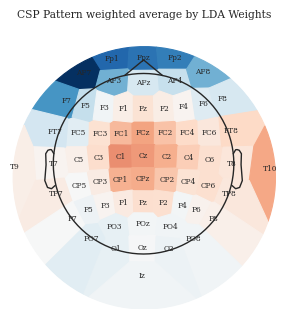

In [30]:
weighted_masks = pipeline[0].patterns_[:n_components].T*lda.coef_[0]
weighted_masks = weighted_masks.T
fig = plt.figure(figsize=(6.3, 4.2))
fig = attribution_topomap(weighted_masks.sum(axis=0), info.ch_names, title="CSP Pattern weighted average by LDA Weights")
fig.set_figheight(4.2)
fig.set_figwidth(3.4)


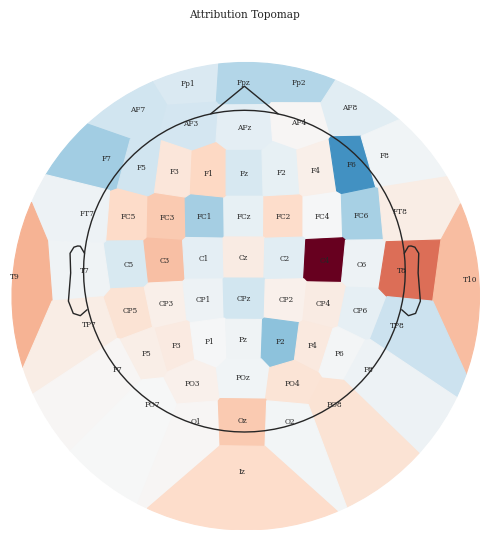

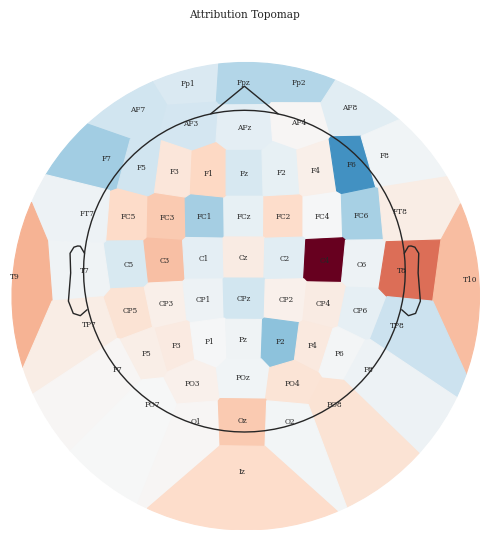

In [31]:
import torch
class csp_lda(torch.nn.Module):
    def __init__(self, pipeline):
        super().__init__()  # Call the constructor of the parent class
        self.pipeline = pipeline
        self.csp_filters = torch.nn.Linear(60, pipeline[0].n_components, bias=False)
        self.lda = torch.nn.Linear(pipeline[0].n_components, 1)
        self.init_weights()
       
    def init_weights(self):
        # Use torch.nn.Parameter to correctly assign weights
        self.csp_filters.weight = torch.nn.Parameter(torch.Tensor(self.pipeline[0].filters_[:self.pipeline[0].n_components]))
        self.lda.weight = torch.nn.Parameter(torch.tensor(self.pipeline[1].coef_[0].reshape(1, -1)))
        self.lda.bias = torch.nn.Parameter(torch.tensor(self.pipeline[1].intercept_))

    def forward(self, x):
        # The forward pass expects log-variance, so we take the log after squaring and averaging
        # x has shape (channels, time_points), linear layer expects (..., features)
        # so we transpose x to (time_points, channels)
        csp_features = torch.log(self.csp_filters(x).square().mean(dim=0))
        lda_features = self.lda(csp_features)
        return lda_features

csp_lda_model = csp_lda(pipeline).to(torch.double)
example = single_epoch_dataset[0]["signal"]
example = torch.tensor(example, dtype=torch.double, requires_grad=True)
csp_lda_model(example.T).backward()
attr = (example*example.grad).detach().numpy()
attribution_topomap(attr.sum(axis=1), info.ch_names)

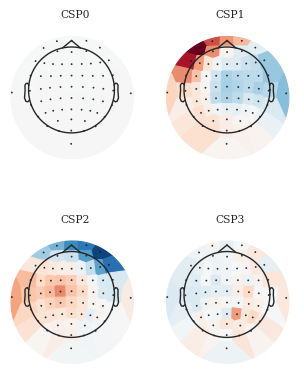

/var/folders/dc/58rzjg0915v8qf5bj5ndjzy00000gp/T/ipykernel_35030/1105660821.py:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  pipeline[0].plot_patterns(info=info, sphere="eeglab", image_interp='nearest', contours=0,nrows=3, colorbar=False).show()


In [32]:
pipeline[0].plot_patterns(info=info, sphere="eeglab", image_interp='nearest', contours=0,nrows=3, colorbar=False).show()

In [ ]:
pipeline[0].plot_filters(info=info, image_interp='nearest', sphere='eeglab', contours=0, nrows=3, colorbar=False).show()